In [1]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
import os
from PIL import Image

2025-06-20 17:24:26.995099: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750440267.294508      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750440267.374229      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
train_dir = '/kaggle/input/covid19-image-dataset/Covid19-dataset/train'
test_dir = '/kaggle/input/covid19-image-dataset/Covid19-dataset/test'

In [3]:
imagens_corrompidas = []

def verificar_imagens(diretorio):
    for root, dirs, files in os.walk(diretorio):
        for file in files:
            caminho = os.path.join(root, file)
            try:
                img = Image.open(caminho)
                img.verify()
            except Exception as e:
                print(f'Imagem corrompida ou inválida: {caminho}')
                imagens_corrompidas.append(caminho)

verificar_imagens(train_dir)
verificar_imagens(test_dir)

print(f'Total de imagens corrompidas encontradas: {len(imagens_corrompidas)}')

Total de imagens corrompidas encontradas: 0


In [4]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2 
)

# Gerador para TREINO
train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64), 
    batch_size=32,
    class_mode='categorical',
    subset='training',  
    seed=42  
)

# Gerador para VALIDAÇÃO
val_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='categorical',
    subset='validation',  
    seed=42
)

# Gerador para TESTE
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  
)

Found 201 images belonging to 3 classes.
Found 50 images belonging to 3 classes.
Found 66 images belonging to 3 classes.


In [5]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-06-20 17:25:03.466916: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,625,539 (6.20 MB)

 Trainable params: 1,625,539 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=20,  
    validation_data=val_generator,
    validation_steps=len(val_generator)
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.4078 - loss: 1.3516 - val_accuracy: 0.6600 - val_loss: 1.0106
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.7644 - loss: 0.9040 - val_accuracy: 0.8000 - val_loss: 0.7199
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 835ms/step - accuracy: 0.8877 - loss: 0.5001 - val_accuracy: 0.9400 - val_loss: 0.3291
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 804ms/step - accuracy: 0.9249 - loss: 0.2546 - val_accuracy: 0.7400 - val_loss: 0.4852
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 927ms/step - accuracy: 0.8887 - loss: 0.2984 - val_accuracy: 0.7800 - val_loss: 0.6159
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 830ms/step - accuracy: 0.9124 - loss: 0.1950 - val_accuracy: 0.9000 - val_loss: 0.2320
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 803ms/step - accuracy: 0.9410 - loss: 0.1542 - val_accuracy: 0.7400 - val_loss: 0.5979
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 782ms/step - accuracy: 0.8915 - loss: 0.2940 - val_accuracy: 0.7600 - val_loss: 0.53

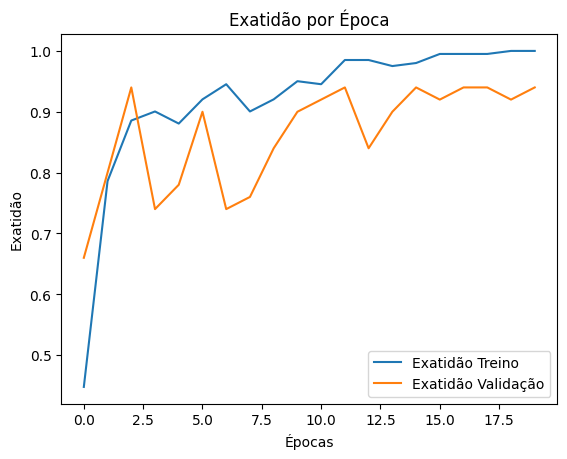

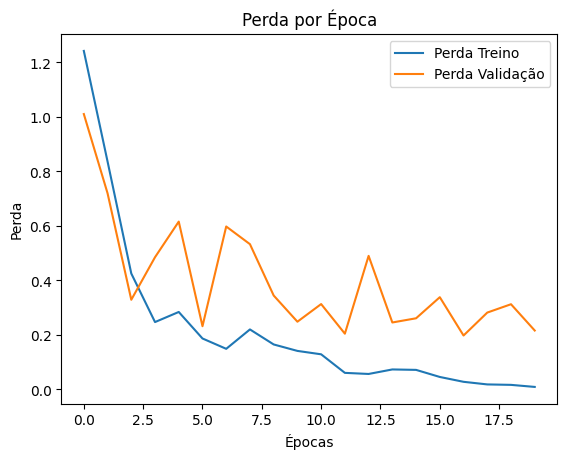

In [7]:
plt.plot(history.history['accuracy'], label='Exatidão Treino')
plt.plot(history.history['val_accuracy'], label='Exatidão Validação')
plt.xlabel('Épocas')
plt.ylabel('Exatidão')
plt.legend()
plt.title('Exatidão por Época')
plt.show()

plt.plot(history.history['loss'], label='Perda Treino')
plt.plot(history.history['val_loss'], label='Perda Validação')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.title('Perda por Época')
plt.show()

In [8]:
test_loss, test_acc = model.evaluate(test_generator, steps=len(test_generator))
print(f'Exatidão do Teste: {test_acc * 100:.2f}%')

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 195ms/step - accuracy: 0.9155 - loss: 0.2145
Exatidão do Teste: 90.91%


In [9]:
img_path = '/kaggle/input/covid19-image-dataset/Covid19-dataset/test/Covid/0115.jpeg'  
img = image.load_img(img_path, target_size=(64, 64))  
img_tensor = image.img_to_array(img)  
img_tensor = np.expand_dims(img_tensor, axis=0)  
img_tensor /= 255.0  

prediction = model.predict(img_tensor)
class_index = np.argmax(prediction[0])

class_names = {
    0: "COVID-19",
    1: "Normal",
    2: "Pneumonia Viral"
}

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


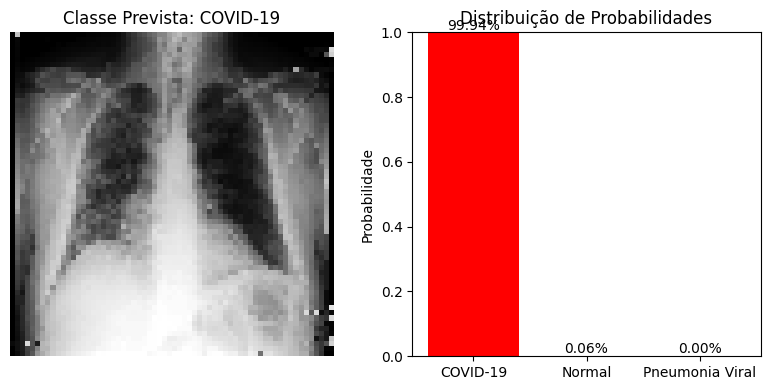


Previsão Final: COVID-19 (99.94%)


In [10]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"Classe Prevista: {class_names[class_index]}")
plt.axis('off')

plt.subplot(1, 2, 2)
bars = plt.bar(class_names.values(), prediction[0], color=['red', 'green', 'blue'])
plt.ylabel('Probabilidade')
plt.title('Distribuição de Probabilidades')
plt.ylim([0, 1])

# Adicionar valores nas barras
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2%}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(f"\nPrevisão Final: {class_names[class_index]} ({prediction[0][class_index]:.2%})")